# 08 Hypothesis testing and experiment design (BQ8): Python version

**BQ8:** Are observed differences between groups real, and how should a future campaign be tested?

- **Part A, hypothesis tests on observed groups** (Year 2, Dec 2010 – Nov 2011): UK vs non-UK order value
  (Welch t-test, Mann–Whitney U, bootstrap confidence intervals), cancellation rate in Q4 vs the rest of the year
  (two-proportion z-test), and order size vs cancellation (chi-square test of independence).
- **Part B, A/B test design:** baseline rates from the data, sample size per group for a win-back email test,
  and the smallest effect detectable with the customers available.

**Important:** this dataset contains no randomised experiment. Part A shows whether differences are larger than chance,
**not what causes them** (UK and non-UK customers differ in many ways at once). Part B plans the experiment that would
answer a causal question.

Same data and tests as `08_hypothesis_ab_r.ipynb`. Test statistics and p-values must match exactly; bootstrap intervals
use random resampling and agree only approximately.

## Setup and data

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROC = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
DASH = ROOT / "reports" / "dashboard_data"
FIG.mkdir(parents=True, exist_ok=True)
DASH.mkdir(parents=True, exist_ok=True)

START, END = "2010-12-01", "2011-12-01"
ALPHA, POWER = 0.05, 0.80
N_BOOT, SEED = 2000, 42

sales = pd.read_parquet(PROC / "sales_clean.parquet")
prod = sales.loc[(sales["line_type"] == "product")
                 & (sales["invoice_date"] >= START) & (sales["invoice_date"] < END)].copy()      # T6
print(f"Year 2 product lines: {len(prod):,}   invoices: {prod['invoice'].nunique():,}")

Year 2 product lines: 497,787   invoices: 18,957


# Part A: Hypothesis tests on observed groups

Every test starts from a **null hypothesis** H0 (no difference) and asks how likely a difference at least as large as
the one observed would be if H0 were true (the **p-value**). With very large samples even tiny differences become
"significant", so each test also reports an **effect size**: how big the difference is in business terms.

Four tests are run, so a Bonferroni-adjusted threshold of 0.05 / 4 = 0.0125 is also shown.

## A1. Order value: UK vs non-UK customers

Orders = invoices with at least one product line not later cancelled; order value = value of those kept lines,
rounded to the penny (so that tied values are identical in Python and R, which matters for the rank-based test).

- **Welch t-test** compares means without assuming equal variances. Order values are very skewed, so it is run on
  log(order value), which compares geometric means (typical order sizes).
- **Mann–Whitney U** compares whole distributions using ranks, with no assumption about their shape.

In [2]:
kept = prod.loc[~prod["cancelled_exact"]]
orders = kept.groupby("invoice").agg(value=("revenue", "sum"), is_uk=("is_uk", "first")).sort_index()
orders["value"] = orders["value"].round(2)        # to the penny: identical ties in Python and R
uk, nonuk = orders.loc[orders["is_uk"], "value"], orders.loc[~orders["is_uk"], "value"]

summ = pd.DataFrame({"orders": [len(uk), len(nonuk)], "mean": [uk.mean(), nonuk.mean()],
                     "median": [uk.median(), nonuk.median()], "geometric_mean": [np.exp(np.log(uk).mean()), np.exp(np.log(nonuk).mean())]},
                    index=["UK", "Non-UK"])
print(summ.round(2).to_string(), "\n")

t_log = stats.ttest_ind(np.log(nonuk), np.log(uk), equal_var=False)
t_raw = stats.ttest_ind(nonuk, uk, equal_var=False)
mw = stats.mannwhitneyu(nonuk, uk, alternative="two-sided", use_continuity=True, method="asymptotic")
ratio = np.exp(np.log(nonuk).mean() - np.log(uk).mean())
prob_sup = mw.statistic / (len(nonuk) * len(uk))      # P(random non-UK order > random UK order)
print(f"Welch t-test, log order value: t = {t_log.statistic:.3f}, df = {t_log.df:.1f}, p = {t_log.pvalue:.3g}   "
      f"(non-UK typical order = {ratio:.2f} x UK)")
print(f"Welch t-test, raw order value: t = {t_raw.statistic:.3f}, df = {t_raw.df:.1f}, p = {t_raw.pvalue:.3g}   "
      f"(difference in means £{nonuk.mean() - uk.mean():,.0f})")
print(f"Mann-Whitney U: U = {mw.statistic:,.0f}, p = {mw.pvalue:.3g}   "
      f"(probability a non-UK order is larger than a UK order: {prob_sup:.3f})")

        orders     mean   median  geometric_mean
UK       17051 464.4600 296.0700        244.8900
Non-UK    1786 816.7900 387.1800        392.5200 

Welch t-test, log order value: t = 16.375, df = 2208.8, p = 5.67e-57   (non-UK typical order = 1.60 x UK)
Welch t-test, raw order value: t = 8.300, df = 1917.7, p = 1.93e-16   (difference in means £352)
Mann-Whitney U: U = 18,697,530, p = 9.46e-57   (probability a non-UK order is larger than a UK order: 0.614)


### Bootstrap confidence intervals

The bootstrap resamples the orders with replacement many times (here 2,000) and recomputes the statistic each time;
the middle 95% of those results is a **percentile confidence interval**. It needs no formula and works for medians,
where textbook formulas are awkward.

                                    estimate   ci_low  ci_high
Median difference (non-UK - UK), £   91.1000  70.8000 114.5000
Mean difference (non-UK - UK), £    352.3000 272.6000 437.8000


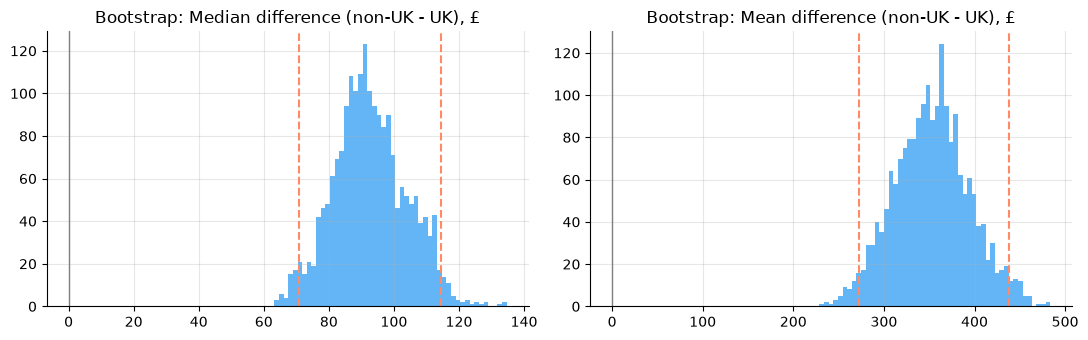

In [3]:
rng = np.random.default_rng(SEED)
u, v = uk.values, nonuk.values
boot = np.empty((N_BOOT, 2))
for b in range(N_BOOT):
    bu, bv = rng.choice(u, len(u)), rng.choice(v, len(v))
    boot[b] = [np.median(bv) - np.median(bu), bv.mean() - bu.mean()]
ci = pd.DataFrame({"estimate": [np.median(v) - np.median(u), v.mean() - u.mean()],
                   "ci_low": np.percentile(boot, 2.5, axis=0), "ci_high": np.percentile(boot, 97.5, axis=0)},
                  index=["Median difference (non-UK - UK), £", "Mean difference (non-UK - UK), £"])
print(ci.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, i, title in [(axes[0], 0, "Median difference"), (axes[1], 1, "Mean difference")]:
    ax.hist(boot[:, i], bins=50, color="#64B5F6")
    ax.axvline(ci.iloc[i]["ci_low"], color="#FF8A65", ls="--"); ax.axvline(ci.iloc[i]["ci_high"], color="#FF8A65", ls="--")
    ax.axvline(0, color="grey", lw=1); ax.set_title(f"Bootstrap: {title} (non-UK - UK), £")
fig.tight_layout(); fig.savefig(FIG / "bq8_bootstrap.png", dpi=150); plt.show()

## A2. Cancellation rate: Q4 (Oct–Dec) vs the rest of the year

Product lines with a customer ID; a line counts as cancelled if it was later cancelled with an exact match (T5).
**Two-proportion z-test** (pooled), equivalent to a chi-square test on the 2 × 2 table.

In [4]:
lc = prod.loc[prod["has_customer"]].copy()
lc["q4"] = lc["invoice_date"].dt.month >= 10
grp = lc.groupby("q4")["cancelled_exact"].agg(["sum", "count"])
x1, n1 = grp.loc[True, "sum"], grp.loc[True, "count"]
x0, n0 = grp.loc[False, "sum"], grp.loc[False, "count"]
p1, p0 = x1 / n1, x0 / n0
pp = (x1 + x0) / (n1 + n0)
z = (p1 - p0) / np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n0))
p_z = 2 * stats.norm.sf(abs(z))
se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
print(f"Q4: {x1:,} of {n1:,} lines cancelled ({p1:.3%})   Rest of year: {x0:,} of {n0:,} ({p0:.3%})")
print(f"Two-proportion z-test: z = {z:.3f}, p = {p_z:.3g}   chi-square = z² = {z**2:.3f}")
print(f"Difference: {100 * (p1 - p0):+.3f} percentage points, 95% CI [{100 * (p1 - p0 - 1.96 * se):+.3f}, "
      f"{100 * (p1 - p0 + 1.96 * se):+.3f}]   relative: {p1 / p0 - 1:+.1%}")

Q4: 838 of 137,118 lines cancelled (0.611%)   Rest of year: 1,939 of 237,071 (0.818%)
Two-proportion z-test: z = -7.100, p = 1.25e-12   chi-square = z² = 50.409
Difference: -0.207 percentage points, 95% CI [-0.262, -0.152]   relative: -25.3%


## A3. Order size and cancellation: chi-square test of independence

Do larger orders contain an exactly cancelled line more often? Orders (all Year 2 product invoices) are grouped by
number of product lines. H0: the share of orders with a cancellation is the same in every size band.
**Cramér's V** measures the strength of association (0 = none, 1 = perfect).

In [5]:
o = prod.groupby("invoice").agg(lines=("stock_code", "size"), has_cancel=("cancelled_exact", "max")).sort_index()
o["size_band"] = pd.cut(o["lines"], bins=[0, 1, 10, 30, np.inf], labels=["1 line", "2-10", "11-30", "31+"])
tab = pd.crosstab(o["size_band"], o["has_cancel"])
chi2, p_chi, dof, expected = stats.chi2_contingency(tab.values, correction=False)
cramers_v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
rates = (tab[True] / tab.sum(axis=1)).rename("share_with_cancellation")
print(pd.concat([tab.rename(columns={False: "no_cancel", True: "with_cancel"}), rates], axis=1).to_string())
print(f"\nChi-square = {chi2:.2f}, df = {dof}, p = {p_chi:.3g}   Cramér's V = {cramers_v:.3f}")

           no_cancel  with_cancel  share_with_cancellation
size_band                                                 
1 line          1387           49                   0.0341
2-10            5365          221                   0.0396
11-30           6958          560                   0.0745
31+             3944          473                   0.1071

Chi-square = 206.52, df = 3, p = 1.64e-44   Cramér's V = 0.104


In [6]:
tests = pd.DataFrame([
    ["Order value, non-UK vs UK", "Welch t-test (log value)", t_log.statistic, t_log.pvalue, f"typical order x{ratio:.2f}"],
    ["Order value, non-UK vs UK", "Mann-Whitney U", mw.statistic, mw.pvalue, f"P(non-UK > UK) = {prob_sup:.3f}"],
    ["Cancellation rate, Q4 vs rest", "Two-proportion z-test", z, p_z, f"{100 * (p1 - p0):+.2f} pp"],
    ["Cancellation vs order size", "Chi-square test", chi2, p_chi, f"Cramér's V = {cramers_v:.3f}"]],
    columns=["comparison", "test", "statistic", "p_value", "effect"])
tests["significant_0.05"] = tests["p_value"] < ALPHA
tests["significant_bonferroni"] = tests["p_value"] < ALPHA / len(tests)
print(tests.to_string())

                      comparison                      test       statistic  p_value                  effect  significant_0.05  significant_bonferroni
0      Order value, non-UK vs UK  Welch t-test (log value)         16.3755   0.0000     typical order x1.60              True                    True
1      Order value, non-UK vs UK            Mann-Whitney U 18,697,530.0000   0.0000  P(non-UK > UK) = 0.614              True                    True
2  Cancellation rate, Q4 vs rest     Two-proportion z-test         -7.0999   0.0000                -0.21 pp              True                    True
3     Cancellation vs order size           Chi-square test        206.5211   0.0000      Cramér's V = 0.104              True                    True


# Part B: Designing an A/B test

**Scenario.** BQ4 and BQ6 identified mid-value customers who are buying less often. Marketing wants to know whether a
win-back email makes them reorder. A valid test **randomly** splits eligible customers into a control group (no email)
and a treatment group (email) and compares the 90-day reorder rates.

**Eligible customers** (as at 1 Sep 2011): last purchase 30–120 days earlier. Their observed 90-day reorder rate is
the **baseline** p0 for the control group.

**Sample size per group** for a two-sided test (α = 0.05, power 80%) to detect a lift from p0 to p1:

`n = (z₁₋α/₂·√(2·p̄·(1−p̄)) + z₁₋β·√(p0(1−p0) + p1(1−p1)))² / (p1 − p0)²`, with p̄ = (p0 + p1) / 2.

In [7]:
cut = pd.Timestamp("2011-09-01")
hist = prod.loc[prod["has_customer"] & ~prod["cancelled_exact"] & (prod["invoice_date"] < cut)]
last = hist.groupby("customer_id")["date"].max()
days = (cut - last).dt.days
elig = days.index[(days >= 30) & (days <= 120)]
after = prod.loc[prod["has_customer"] & ~prod["cancelled_exact"] & (prod["invoice_date"] >= cut)
                 & (prod["invoice_date"] < cut + pd.Timedelta(days=90)), "customer_id"].unique()
p0 = float(np.isin(elig, after).mean())
print(f"Eligible customers: {len(elig):,}   baseline 90-day reorder rate p0 = {p0:.1%}")

z_a, z_b = stats.norm.ppf(1 - ALPHA / 2), stats.norm.ppf(POWER)
def n_per_group(p0, p1):
    pbar = (p0 + p1) / 2
    return int(np.ceil((z_a * np.sqrt(2 * pbar * (1 - pbar)) + z_b * np.sqrt(p0 * (1 - p0) + p1 * (1 - p1))) ** 2 / (p1 - p0) ** 2))

plan = pd.DataFrame([{"lift_pp": d, "p_control": p0, "p_treatment": p0 + d / 100,
                      "n_per_group": n_per_group(p0, p0 + d / 100)} for d in [2, 3, 5, 7.5, 10]])
plan["n_total"] = 2 * plan["n_per_group"]
plan["share_of_eligible"] = plan["n_total"] / len(elig)
print(plan.to_string(index=False))

Eligible customers: 1,408   baseline 90-day reorder rate p0 = 59.2%
 lift_pp  p_control  p_treatment  n_per_group  n_total  share_of_eligible
  2.0000     0.5916       0.6116         9405    18810            13.3594
  3.0000     0.5916       0.6216         4162     8324             5.9119
  5.0000     0.5916       0.6416         1484     2968             2.1080
  7.5000     0.5916       0.6666          650     1300             0.9233
 10.0000     0.5916       0.6916          360      720             0.5114


**Minimum detectable effect (MDE).** If all eligible customers are used, split 50/50, what is the smallest lift the test
can reliably detect? Solved numerically from the same formula.

Customers per group if all eligible are used: 704
Minimum detectable lift: 7.21 percentage points (59.2% -> 66.4%)


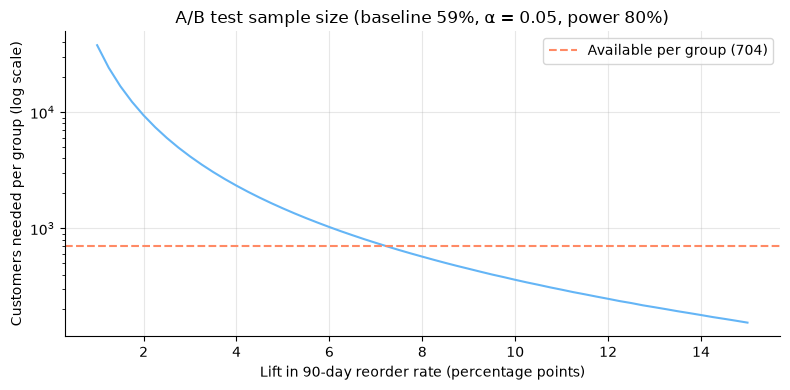

In [8]:
n_avail = len(elig) // 2
lo, hi = 1e-6, 1 - p0 - 1e-6
for _ in range(100):                                    # bisection on the lift
    mid = (lo + hi) / 2
    if n_per_group(p0, p0 + mid) > n_avail: lo = mid
    else: hi = mid
mde = hi
print(f"Customers per group if all eligible are used: {n_avail:,}")
print(f"Minimum detectable lift: {100 * mde:.2f} percentage points ({p0:.1%} -> {p0 + mde:.1%})")

d_grid = np.linspace(0.01, 0.15, 57)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(d_grid * 100, [n_per_group(p0, p0 + d) for d in d_grid], color="#64B5F6")
ax.axhline(n_avail, color="#FF8A65", ls="--", label=f"Available per group ({n_avail:,})")
ax.set_yscale("log"); ax.set_xlabel("Lift in 90-day reorder rate (percentage points)")
ax.set_ylabel("Customers needed per group (log scale)")
ax.set_title(f"A/B test sample size (baseline {p0:.0%}, α = 0.05, power 80%)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "bq8_sample_size.png", dpi=150); plt.show()

**Secondary metric: order value.** To detect a 5% higher typical order value (on the log scale), the sample size per
group is `n = 2·(z₁₋α/₂ + z₁₋β)²·σ² / δ²`, with σ the standard deviation of log order value and δ = log(1.05).

In [9]:
sigma = np.log(orders["value"]).std()
n_aov = {lift: int(np.ceil(2 * (z_a + z_b) ** 2 * sigma ** 2 / np.log(1 + lift) ** 2)) for lift in [0.05, 0.10]}
print(f"SD of log order value: {sigma:.4f}")
for lift, n in n_aov.items():
    print(f"Orders per group to detect a {lift:.0%} higher typical order value: {n:,}")

SD of log order value: 1.2031
Orders per group to detect a 5% higher typical order value: 9,546
Orders per group to detect a 10% higher typical order value: 2,502


## Export for the dashboard

In [10]:
tests.round(6).to_csv(DASH / "hypothesis_tests.csv", index=False)
ci.round(4).rename_axis("statistic").to_csv(DASH / "bootstrap_intervals.csv")
plan.round(6).to_csv(DASH / "ab_sample_size.csv", index=False)
for f in ["hypothesis_tests.csv", "bootstrap_intervals.csv", "ab_sample_size.csv"]:
    print(f"{f:<26} {len(pd.read_csv(DASH / f)):>3} rows")

hypothesis_tests.csv         4 rows
bootstrap_intervals.csv      2 rows
ab_sample_size.csv           5 rows
